# 04 — Tier 1 model: yearly susceptibility ranking

**In plain words:** this notebook teaches computer models to rank the 552 lakes each year by how *susceptible* they
are to an outburst, using the frozen clues from notebook 03. It then checks honestly how good the ranking is.

| Output | What it is |
| --- | --- |
| `ranking.csv` | risk score and rank of every lake for 2020–2025 (the app's map and top-10 list) |
| `shap_top.csv` | for every lake-year 2020–2025, the 5 clues that pushed its score up or down, as sentences |
| `metrics_tier1.json` | all results with 95% confidence intervals, the ablation and the honesty checks |
| `test_predictions.csv`, `event_ranks.csv`, `leave_one_lake_out.csv`, `validation.csv` | the evidence behind the numbers |
| figures, `lightgbm_model.txt`, `run_info.json` | precision-recall curves, calibration, feature importance, the model |

**Rules followed (each one is checked or enforced in a cell below):**
* **Time-based split, never shuffled:** learn on 2000–2017, tune on 2018–2019, test on 2020–2025.
* **The test years are scored once.** The first run saves the test predictions with a timestamp; any later run loads
  them instead of scoring again, so nothing can be tuned after looking at the test results.
* **Rare floods handled with class weights** (a missed flood counts more), never with invented examples (SMOTE).
* **Right metrics only:** PR-AUC, recall at top-10, Brier score, each with a bootstrap 95% interval. Never accuracy.
* **Honesty checks (owner decision):** where each test flood's lake ranked, and **leave-one-lake-out**: does the model
  still rank Shisper (or Khurdopin) high if it never saw that lake while learning?

**How to run:** open from the GitHub link, Runtime → Run all. Send back the cells marked **📋 REPORT** and the figures.

## 0. Setup
The model code (`karaglof.models`), the metrics (`karaglof.metrics`) and the sentences (`karaglof.explain`) are the
tested code from the repository. The frozen dataset is read from the repository (`data/features/`, v0.4).

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/inamjadoon/KaraGlof.git"
REPO_DIR = "/content/KaraGlof"
if os.path.isdir(REPO_DIR):
    subprocess.run(["git", "-C", REPO_DIR, "pull", "-q"], check=True)
else:
    subprocess.run(["git", "clone", "-q", REPO_URL, REPO_DIR], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm==4.5.0", "shap==0.48.0"], check=True)
sys.path.insert(0, f"{REPO_DIR}/src")
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--oneline"],
                     capture_output=True, text=True).stdout)

d01ebff data: add the frozen parquet tables and data dictionary (were blocked by .gitignore)



In [2]:
import json
from datetime import UTC, datetime
from pathlib import Path

import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
from google.colab import drive
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve

from karaglof import SEED
from karaglof import explain as kx
from karaglof import features as kf
from karaglof import metrics as km
from karaglof import models as kmod

drive.mount("/content/drive")
OUT = Path("/content/drive/MyDrive/KaraGlof/04_tier1")
OUT.mkdir(parents=True, exist_ok=True)
DATA = Path(REPO_DIR) / "data"
FEATURES = kf.FEATURES
GLACIER = kf.FEATURE_GROUPS["glacier"]
TOP_K = 10
TIER2 = {"Shisper": "KG-HUN-363", "Khurdopin": "KG-SHM-068"}   # lakes with test-year outbursts
print("seed", SEED, "| features:", len(FEATURES))

Mounted at /content/drive
seed 42 | features: 15


## 1. Load the frozen dataset and split by time 📋 REPORT

In [3]:
data = pd.read_parquet(DATA / "features" / "lake_year.parquet")
lakes = pd.read_csv(DATA / "labels" / "lakes.csv", keep_default_na=False)
data["split"] = km.split_of(data.year)
train, val, test = (data[data.split == s].copy() for s in ("train", "validation", "test"))
fit = data[data.split.isin(["train", "validation"])].copy()          # 2000-2019, for the final models
print(data.groupby("split", sort=False).glof.agg(lake_years="size", positives="sum").to_string())
print("\npositive lake-years:")
print(data[data.glof == 1].merge(lakes[["lake_id", "name"]], on="lake_id")
      .groupby(["name", "split"], sort=False).year.apply(list).to_string())
assert set(data.columns) >= set(FEATURES) and "dam_type" not in data.columns

            lake_years  positives
split                            
train             9936          7
validation        1104          3
test              3312          5

positive lake-years:
name       split     
Passu      train                                 [2008]
Shisper    train                                 [2002]
           validation                            [2019]
           test                [2020, 2021, 2022, 2025]
Khurdopin  train         [2000, 2001, 2002, 2003, 2017]
           validation                      [2018, 2019]
           test                                  [2021]


## 2. Learn on 2000–2017, compare on 2018–2019 📋 REPORT
Three models, simplest first:
* **logistic regression** (the baseline: a weighted straight-line rule);
* **Random Forest** (many decision trees voting);
* **LightGBM** (trees built one after another, each fixing the last one's mistakes). It is the only model that is
  *tuned*, and only over a tiny grid (`karaglof.models.LGBM_GRID`, 8 settings), because the validation years
  hold only 3 floods: a big search would just fit noise.

In [4]:
best, grid = kmod.tune_lightgbm(train, val, FEATURES)
print("LightGBM settings tried on 2018-2019 (validation PR-AUC):")
print(grid.round(3).to_string(index=False))
print("chosen:", best)

def make(name, feats, data_for_weight):
    if name == "logistic_baseline":
        return kmod.logistic()
    if name == "random_forest":
        return kmod.random_forest()
    return kmod.lightgbm(kmod.pos_weight(data_for_weight.glof), **best)

MODELS = ["logistic_baseline", "random_forest", "lightgbm"]
rows = []
for name in MODELS:
    m = make(name, FEATURES, train).fit(train[FEATURES], train.glof)
    v = val.assign(score=kmod.score(m, val, FEATURES))
    rows.append({"model": name, **km.all_metrics(v, "score", TOP_K)})
validation = pd.DataFrame(rows)
print("\nValidation 2018-2019 (3 floods; for choosing settings only):")
print(validation.round(3).to_string(index=False))

LightGBM settings tried on 2018-2019 (validation PR-AUC):
 num_leaves  min_child_samples  n_estimators  val_pr_auc
          3                 10           100       0.756
          3                 10           300       0.738
          3                  3           100       0.756
          3                  3           300       0.733
          7                 10           100       0.833
          7                 10           300       0.700
          7                  3           100       0.756
          7                  3           300       0.622
chosen: {'num_leaves': 7, 'min_child_samples': 10, 'n_estimators': 100}

Validation 2018-2019 (3 floods; for choosing settings only):
            model  pr_auc  recall_at_top10  brier
logistic_baseline   0.472              1.0  0.008
    random_forest   0.867              1.0  0.001
         lightgbm   0.833              1.0  0.002


## 3. Score the test years 2020–2025 **once** 📋 REPORT
The final models learn on 2000–2019 (train + validation) with the settings chosen above, then score 2020–2025.
The predictions are saved **immediately** with a timestamp in `test_predictions.csv`. If that file already exists
(a rerun), it is loaded instead, so the test result can never be "improved" by trying again.

The **ablation** model (LightGBM without the 4 glacier-speed and surge features) is trained and scored in the same
step, with the same settings, so the comparison answers the research question fairly.

In [5]:
pred_file = OUT / "test_predictions.csv"
lock_file = OUT / "TEST_SCORED_ONCE.json"
if pred_file.exists() and lock_file.exists():
    preds = pd.read_csv(pred_file)
    lock = json.loads(lock_file.read_text())
    print(f"Test years were already scored on {lock['scored_utc']}: loading the saved predictions, NOT re-scoring.")
else:
    preds = test[["lake_id", "year", "glof"]].copy()
    final = {}
    for name in MODELS:
        final[name] = make(name, FEATURES, fit).fit(fit[FEATURES], fit.glof)
        preds[name] = kmod.score(final[name], test, FEATURES)
    no_glacier = [f for f in FEATURES if f not in GLACIER]
    final["lightgbm_without_glacier"] = kmod.lightgbm(kmod.pos_weight(fit.glof), **best).fit(fit[no_glacier], fit.glof)
    preds["lightgbm_without_glacier"] = kmod.score(final["lightgbm_without_glacier"], test, no_glacier)
    preds.to_csv(pred_file, index=False)
    lock = {"scored_utc": datetime.now(UTC).isoformat(timespec="seconds"), "lightgbm_params": best,
            "train_years": "2000-2019", "test_years": "2020-2025"}
    lock_file.write_text(json.dumps(lock, indent=2))
    final["lightgbm"].booster_.save_model(str(OUT / "lightgbm_model.txt"))
    print(f"Test years scored once at {lock['scored_utc']}; predictions saved.")
# the final LightGBM is needed for SHAP even on a rerun (same data, same seed -> same model)
final_lgbm = kmod.lightgbm(kmod.pos_weight(fit.glof), **lock["lightgbm_params"]).fit(fit[FEATURES], fit.glof)
assert np.allclose(kmod.score(final_lgbm, test, FEATURES), preds.lightgbm.values), "model is not reproducible"

no_skill = preds.glof.mean()
results = []
for name in MODELS + ["lightgbm_without_glacier"]:
    point = km.all_metrics(preds, name, TOP_K)
    ci = km.bootstrap_ci(preds, name, TOP_K)
    results.append({"name": name, **point, **ci})
res = pd.DataFrame(results)
show = res[["name", "pr_auc", "pr_auc_ci95", f"recall_at_top{TOP_K}", f"recall_at_top{TOP_K}_ci95", "brier", "brier_ci95"]]
print(f"Test 2020-2025: {int(preds.glof.sum())} floods in {len(preds)} lake-years; "
      f"no-skill PR-AUC = {no_skill:.4f}\n")
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 200):
    print(show.to_string(index=False))

Test years scored once at 2026-11-19T14:34:46+00:00; predictions saved.
Test 2020-2025: 5 floods in 3312 lake-years; no-skill PR-AUC = 0.0015

                    name  pr_auc                                pr_auc_ci95  recall_at_top10 recall_at_top10_ci95  brier                                     brier_ci95
       logistic_baseline  0.3359 [0.043478260869565216, 0.4443106070074574]           0.8000          [0.75, 1.0] 0.0131    [0.008103523043767331, 0.01926870518648011]
           random_forest  0.7556                  [0.7019230769230769, 1.0]           1.0000           [1.0, 1.0] 0.0009 [7.279313429391759e-06, 0.0024417156633692936]
                lightgbm  0.4779               [0.0625, 0.6791666666666667]           1.0000           [1.0, 1.0] 0.0022  [0.0002768150322647805, 0.004669611609978128]
lightgbm_without_glacier  0.2307                [0.125, 0.5011904761904762]           1.0000           [1.0, 1.0] 0.0028 [0.00016382721111086183, 0.006280495310847532]


## 4. Honesty check 1: where did each test flood's lake rank? 📋 REPORT
With only 5 test floods, the clearest result is simply the rank (out of 552) of each flooding lake in its year.

In [6]:
ranks = km.event_ranks(preds, "lightgbm").merge(lakes[["lake_id", "name"]], on="lake_id")
print(ranks[["name", "lake_id", "year", "rank", "lakes_that_year", "lightgbm"]].round(4).to_string(index=False))

     name    lake_id  year  rank  lakes_that_year  lightgbm
  Shisper KG-HUN-363  2020     1              552    0.9934
  Shisper KG-HUN-363  2021     1              552    0.9941
  Shisper KG-HUN-363  2022     1              552    0.9402
  Shisper KG-HUN-363  2025     2              552    0.9437
Khurdopin KG-SHM-068  2021     2              552    0.2442


## 5. Honesty check 2: leave one lake out 📋 REPORT
For Shisper and then Khurdopin: train LightGBM on 2000–2019 **without that lake at all**, score 2020–2025, and see
where the unseen lake ranks in its flood years. A high rank means the model learned general warning signs (for
example glacier surges and lake growth) that it can recognise in a lake it has never seen. A low rank means the full
model's success mainly came from knowing that lake.

In [7]:
lolo_rows = []
for name, lid in TIER2.items():
    out = kmod.leave_one_lake_out(data, lid, FEATURES, lock["lightgbm_params"], (2000, 2019), (2020, 2025))
    r = km.event_ranks(out, "score")
    for e in r[r.lake_id == lid].itertuples():
        full_rank = ranks[(ranks.lake_id == lid) & (ranks.year == e.year)]["rank"].iloc[0]
        lolo_rows.append({"lake_left_out": name, "year": e.year, "rank_without_seeing_lake": e.rank,
                          "rank_full_model": full_rank, "lakes_that_year": e.lakes_that_year})
lolo = pd.DataFrame(lolo_rows)
print(lolo.to_string(index=False))

lake_left_out  year  rank_without_seeing_lake  rank_full_model  lakes_that_year
      Shisper  2020                       538                1              552
      Shisper  2021                        73                1              552
      Shisper  2022                       407                1              552
      Shisper  2025                        91                2              552
    Khurdopin  2021                       393                2              552


## 6. Ablation: do the glacier-surge features help? 📋 REPORT
This is the research question. PR-AUC of LightGBM **with** minus **without** the glacier group, with a *paired*
bootstrap interval (the same resampled lakes for both models). With 5 test floods the interval will be wide;
the result is reported whatever it is.

In [8]:
abl = km.paired_delta_ci(preds, "lightgbm", "lightgbm_without_glacier")
without = res.set_index("name").loc["lightgbm_without_glacier"]
print(f"PR-AUC with glacier features   : {res.set_index('name').loc['lightgbm', 'pr_auc']:.4f}")
print(f"PR-AUC without glacier features: {without.pr_auc:.4f}  CI {np.round(without.pr_auc_ci95, 4).tolist()}")
print(f"difference (with - without)    : {abl['delta_pr_auc']:+.4f}  CI {np.round(abl['delta_pr_auc_ci95'], 4).tolist()}"
      f"  ({abl['n_boot']} usable resamples)")

PR-AUC with glacier features   : 0.4779
PR-AUC without glacier features: 0.2307  CI [0.125, 0.5012]
difference (with - without)    : +0.2472  CI [-0.0625, 0.3231]  (844 usable resamples)


## 7. Explanations (SHAP) 📋 REPORT
SHAP splits each lake-year's score into one contribution per clue. The figure shows which clues matter most overall
(test years); `shap_top.csv` keeps the 5 biggest per lake-year as sentences for the app.

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:583: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


dist_to_glacier_m          0.8830
parent_glacier_km2         0.7625
elev_m                     0.6982
snowmelt_prev_summer_mm    0.4461
pdd_prev_summer            0.4378
surge_ratio_prev           0.3800
heat_anomaly_prev          0.3157
slope_around_deg           0.1900
area_km2_prev              0.1872
area_growth_3y_pct         0.1310
velocity_prev              0.0833
precip_prev_summer_mm      0.0537
velocity_change            0.0390
area_trend_km2_per_yr      0.0204
surge_flag_prev            0.0156


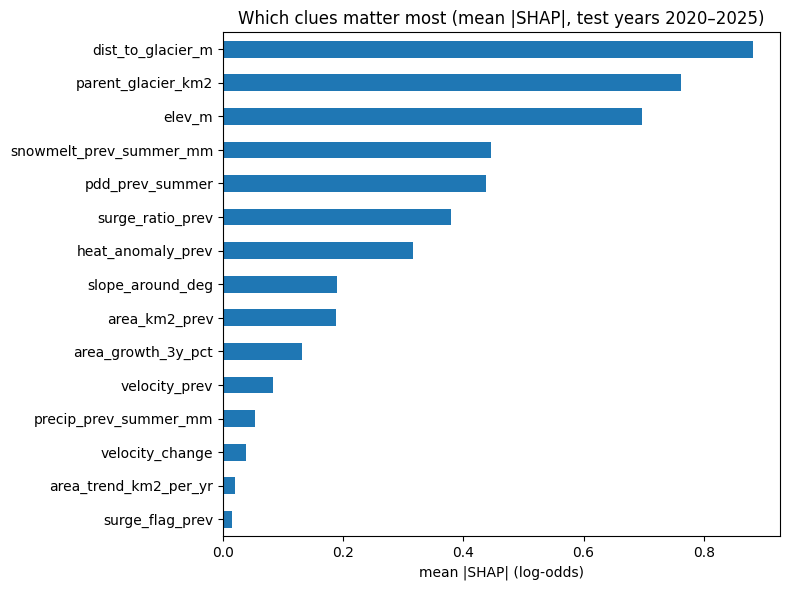

   lake_id  year                 feature value    shap                                                                       text
KG-HUN-363  2022       dist_to_glacier_m   203 12.7654              Distance to the nearest glacier: 203 m: raises susceptibility
KG-HUN-363  2022                  elev_m  2705 11.1750                              Lake elevation: 2705 m: raises susceptibility
KG-HUN-363  2022      parent_glacier_km2 36.81 -7.3344                       Parent glacier area: 36.8 km²: lowers susceptibility
KG-HUN-363  2022 snowmelt_prev_summer_mm 522.4 -4.1877                      Last summer's snowmelt: 522 mm: lowers susceptibility
KG-HUN-363  2022        surge_ratio_prev 1.788  2.7650 Nearby glacier moved 1.8× its usual speed last year: raises susceptibility


In [9]:
X_test = test[FEATURES].reset_index(drop=True)
sv = shap.TreeExplainer(final_lgbm).shap_values(X_test)
sv = sv[1] if isinstance(sv, list) else sv
sv = pd.DataFrame(sv, columns=FEATURES)
shap_top = kx.top_drivers(sv, X_test, test[["lake_id", "year"]].reset_index(drop=True), n=5)
importance = sv.abs().mean().sort_values()
print(importance.sort_values(ascending=False).round(4).to_string())
fig, ax = plt.subplots(figsize=(8, 6))
importance.plot.barh(ax=ax, color="#1f77b4")
ax.set_title("Which clues matter most (mean |SHAP|, test years 2020–2025)")
ax.set_xlabel("mean |SHAP| (log-odds)")
fig.tight_layout()
fig.savefig(OUT / "fig_04_shap_importance.png", dpi=150)
plt.show()
print(shap_top[shap_top.lake_id == TIER2["Shisper"]].query("year == 2022").to_string(index=False))

## 8. Figures: precision-recall and calibration 📋 REPORT
* **Precision-recall:** for each model, how many of the highest-ranked lakes really flooded, as the list gets longer.
  The dashed line is "no skill" (the share of floods).
* **Calibration:** do lakes scored 30% flood about 30% of the time? Class weights push scores up on purpose (a missed
  flood counts more), so the scores are **rankings, not probabilities**. This plot shows by how much.

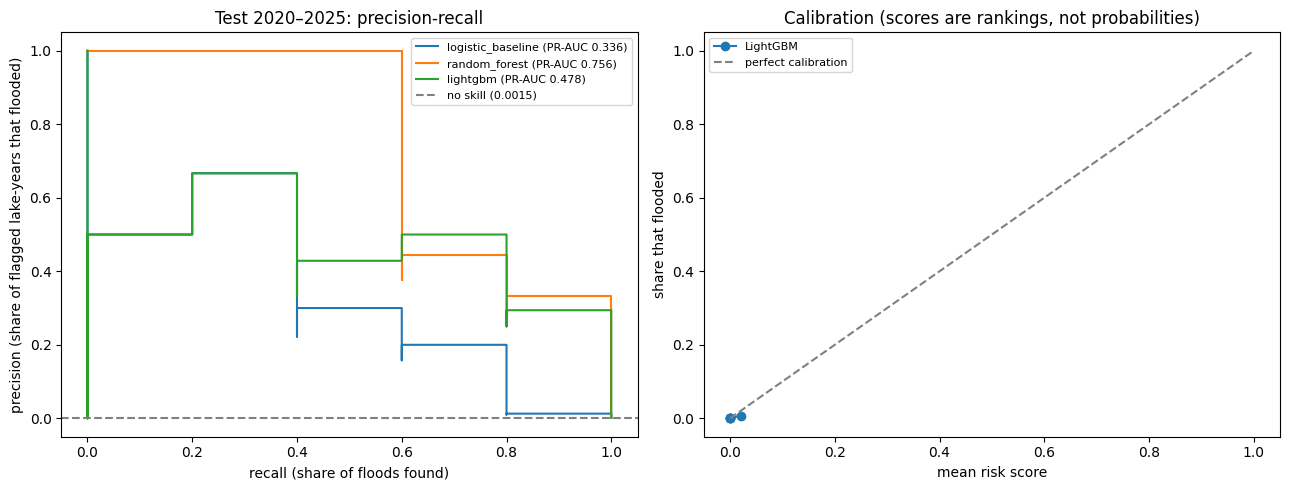

In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
for name in MODELS:
    p, r, _ = precision_recall_curve(preds.glof, preds[name])
    a1.step(r, p, where="post", label=f"{name} (PR-AUC {km.pr_auc(preds.glof, preds[name]):.3f})")
a1.axhline(no_skill, ls="--", color="grey", label=f"no skill ({no_skill:.4f})")
a1.set_xlabel("recall (share of floods found)")
a1.set_ylabel("precision (share of flagged lake-years that flooded)")
a1.set_title("Test 2020–2025: precision-recall")
a1.legend(fontsize=8)
frac, mean_pred = calibration_curve(preds.glof, preds.lightgbm.clip(0, 1), n_bins=5, strategy="quantile")
a2.plot(mean_pred, frac, marker="o", label="LightGBM")
a2.plot([0, 1], [0, 1], ls="--", color="grey", label="perfect calibration")
a2.set_xlabel("mean risk score")
a2.set_ylabel("share that flooded")
a2.set_title("Calibration (scores are rankings, not probabilities)")
a2.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "fig_04_pr_calibration.png", dpi=150)
plt.show()

## 9. Save the released files
* `ranking.csv` (lake_id, year, risk_score, rank) and `shap_top.csv` (lake_id, year, feature, value, shap, text):
  the SPECS §3 files the app serves, for 2020–2025 from the final LightGBM.
* `metrics_tier1.json`: everything above; notebook 05 adds the Tier 2 part to make the app's `metrics.json`.

In [11]:
# rank on the full-precision score (rounding first would create ties among the many tiny scores)
ranking = preds[["lake_id", "year"]].assign(risk_score=preds.lightgbm)
ranking["rank"] = ranking.groupby("year").risk_score.rank(ascending=False, method="first").astype(int)
ranking.sort_values(["year", "rank"]).to_csv(OUT / "ranking.csv", index=False)
shap_top.to_csv(OUT / "shap_top.csv", index=False)
ranks.to_csv(OUT / "event_ranks.csv", index=False)
lolo.to_csv(OUT / "leave_one_lake_out.csv", index=False)
validation.to_csv(OUT / "validation.csv", index=False)

def model_entry(r):
    return {"name": r["name"], "pr_auc": r["pr_auc"], "pr_auc_ci95": r["pr_auc_ci95"],
            f"recall_at_top{TOP_K}": r[f"recall_at_top{TOP_K}"],
            f"recall_at_top{TOP_K}_ci95": r[f"recall_at_top{TOP_K}_ci95"],
            "brier": r["brier"], "brier_ci95": r["brier_ci95"]}

metrics = {
    "data_version": "data-v1", "model_version": "model-1.0.0",
    "tier1": {
        "split": {k: list(v) for k, v in km.SPLITS.items()}, "test_scored_once": True,
        "test_scored_utc": lock["scored_utc"], "positives": data.groupby("split").glof.sum().astype(int).to_dict(),
        "no_skill_pr_auc": float(no_skill), "lightgbm_params": lock["lightgbm_params"],
        "models": [model_entry(r) for r in results if r["name"] in MODELS],
        "ablation": {"feature_group_removed": "glacier", "features": GLACIER,
                     "pr_auc_without_group": float(without.pr_auc),
                     "pr_auc_without_group_ci95": list(without.pr_auc_ci95),
                     "delta_pr_auc": float(abl["delta_pr_auc"]), "delta_pr_auc_ci95": abl["delta_pr_auc_ci95"],
                     "note": "Paired bootstrap over lakes; few test floods, so the interval is wide."},
        "event_ranks": ranks[["name", "year", "rank", "lakes_that_year"]].to_dict(orient="records"),
        "leave_one_lake_out": lolo.to_dict(orient="records"),
    },
}
(OUT / "metrics_tier1.json").write_text(json.dumps(metrics, indent=2, default=float))
run_info = {"notebook": "04_tier1_model", "run_utc": datetime.now(UTC).isoformat(timespec="seconds"),
            "versions": {"lightgbm": lightgbm.__version__, "shap": shap.__version__,
                         "scikit-learn": sklearn.__version__, "pandas": pd.__version__}}
(OUT / "run_info.json").write_text(json.dumps(run_info, indent=2))
print(sorted(p.name for p in OUT.iterdir()))

['TEST_SCORED_ONCE.json', 'event_ranks.csv', 'fig_04_pr_calibration.png', 'fig_04_shap_importance.png', 'leave_one_lake_out.csv', 'lightgbm_model.txt', 'metrics_tier1.json', 'ranking.csv', 'run_info.json', 'shap_top.csv', 'test_predictions.csv', 'validation.csv']


## What to send back
1. The output of every cell marked **📋 REPORT** (steps 1–8).
2. The three figures.

**Do not re-run step 3 hoping for better numbers:** it will only load the saved predictions. That is the point.